In [171]:
# Local steps to run in pycharm
# conda activate sage
# jupyter lab --no-browser --port=8888
# configure external server with the token
# sagemath (10.7)

from sage.all import *
from sage.plot.plot import graphics_array
from itertools import combinations, permutations
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
})

def graph_square(H):
    G = Graph()
    G.add_vertices(H.vertices())
    for u in H.vertices():
        for v in H.vertices():
            if u < v and H.distance(u,v) <= 2:
                G.add_edge(u,v)
    return G

def is_square_root(G, H):
    return graph_square(H) == G

In [172]:
def violates_partial(G, H):
    for u, v in combinations(H.vertices(), 2):
        try:
            d = H.distance(u, v)
        except (ValueError, RuntimeError):
            continue

        if H.has_edge(u, v) and not G.has_edge(u, v):
            return True
        if d <= 2 and not G.has_edge(u, v):
            return True
    return False

def find_all_square_roots(G):

    V = list(G.vertices())
    n = len(V)

    edges_G = set(tuple(sorted(e)) for e in G.edges(labels=False))

    from itertools import combinations
    all_edges = list(combinations(V,2))

    labeled_count = 0
    canonical_roots = {}

    def backtrack(idx, current_edges):

        nonlocal labeled_count

        if idx == len(all_edges):

            H = Graph()
            H.add_vertices(V)
            H.add_edges(current_edges)

            H2 = graph_square(H)
            edges_H2 = set(tuple(sorted(e)) for e in H2.edges(labels=False))

            if edges_H2 == edges_G:

                labeled_count += 1

                canon = H.canonical_label()
                key = canon.graph6_string()

                if key not in canonical_roots:
                    canonical_roots[key] = H.copy()

            return


        u,v = all_edges[idx]

        new_edges = current_edges + [(u,v)]

        H_partial = Graph()
        H_partial.add_vertices(V)
        H_partial.add_edges(new_edges)

        H2 = graph_square(H_partial)

        valid = True
        for e in H2.edges(labels=False):
            if tuple(sorted(e)) not in edges_G:
                valid = False
                break

        if valid:
            backtrack(idx+1,new_edges)

        backtrack(idx+1,current_edges)

    backtrack(0,[])

    return {
        "labeled": labeled_count,
        "non_isomorphic": list(canonical_roots.values())
    }

In [173]:
# LP with max objective function
def max_linear_program(G):
    m = MixedIntegerLinearProgram(solver='Gurobi', maximization=True)
    m.solver_parameter("Method", 2)

    x = m.new_variable(real=True, nonnegative=True)
    y = m.new_variable(real=True, nonnegative=True)
    z = m.new_variable(real=True, nonnegative=True)

    A_G = G.adjacency_matrix()
    n = A_G.nrows()
    M = n**2

    # Indicator argument
    for i in range(n):
        for j in range(n):
            if i == j:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) - sum(x[i,k] for k in range(n)) + x[i,j]) == 0)
            else:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) + x[i,j]) == 0)

    # Indicator function
    for i in range(n):
        for j in range(n):
            m.add_constraint(z[i,j] - M * A_G[i][j] <= 0)
            m.add_constraint(-z[i,j] + A_G[i][j] <= 0)

    # Product
    for i in range(n):
        for j in range(n):
            for k in range(n):
                m.add_constraint(y[i,k,j] - x[i,k] <= 0)
                m.add_constraint(y[i,k,j] - x[k,j] <= 0)
                m.add_constraint(- y[i,k,j] + x[i,k] + x[k,j] - 1 <= 0)

    # Symmetry
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] == x[j,i])

    # Diagonal
    for i in range(n):
        m.add_constraint(x[i,i] == 0)

    # Variables
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] - 1 <= 0)
            for k in range(n):
                m.add_constraint(y[i,k,j] - 1 <= 0)

    m.set_objective(- m.sum(x[i,j] for i in range(n) for j in range(n)))
    return m, x

# O(n^3)
def find_leaf_stem(G, verbose=False):
    n = G.order()
    N = {v: set(G.neighbors(v)) | {v} for v in range(n)}
    signature = {v: frozenset(N[v]) for v in range(n)}

    contained = [[False] * n for _ in range(n)]
    proper = [[False] * n for _ in range(n)]

    for u in range(n):
        for v in range(n):
            if N[u] <= N[v]:
                contained[u][v] = True
                proper[u][v] = N[u] != N[v]

    for s in range(n):
        for u in N[s] - {s}:
            if not proper[s][u]:
                continue

            for v in N[u] - {u}:
                if not contained[u][v]:
                    continue

                leaves = N[s] - {u, v}

                if all(signature[w] == signature[s] for w in leaves):
                    if verbose:
                        print(f"Leaf found: leaf={s}, stem={u}, vertex={v}, leaves={leaves}")

                    return {
                        "leaf": s,
                        "stem": u,
                        "vertex": v,
                        "leaves": leaves
                    }

    return None

# LP with unicliqual vertex fixing in maximal clique
def unicliqual_vertex_linear_program(G, verbose=False):
    m = MixedIntegerLinearProgram(solver='Gurobi', maximization=True)
    m.solver_parameter("Method", 2)

    x = m.new_variable(real=True, nonnegative=True)
    y = m.new_variable(real=True, nonnegative=True)
    z = m.new_variable(real=True, nonnegative=True)

    A_G = G.adjacency_matrix()
    n = A_G.nrows()
    M = n**2

    # Indicator argument
    for i in range(n):
        for j in range(n):
            if i == j:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) - sum(x[i,k] for k in range(n)) + x[i,j]) == 0)
            else:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) + x[i,j]) == 0)

    # Indicator function
    for i in range(n):
        for j in range(n):
            m.add_constraint(z[i,j] - M * A_G[i][j] <= 0)
            m.add_constraint(-z[i,j] + A_G[i][j] <= 0)

    # Product
    for i in range(n):
        for j in range(n):
            for k in range(n):
                m.add_constraint(y[i,k,j] - x[i,k] <= 0)
                m.add_constraint(y[i,k,j] - x[k,j] <= 0)
                m.add_constraint(- y[i,k,j] + x[i,k] + x[k,j] - 1 <= 0)

    # Symmetry
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] == x[j,i])

    # Diagonal
    for i in range(n):
        m.add_constraint(x[i,i] == 0)

    # Variables
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] - 1 <= 0)
            for k in range(n):
                m.add_constraint(y[i,k,j] - 1 <= 0)

    m.set_objective(-m .sum(x[i, j] for i in range(n) for j in range(n)))

    # Find a leaf-stem structure using the largest closed neighbourhood clique
    structure = find_leaf_stem(G, verbose=verbose)

    if structure is None:
        return m, x

    s = structure["leaf"]
    u = structure["stem"]

    m.add_constraint(x[s, u] == 1)
    m.add_constraint(x[u, s] == 1)

    if verbose:
        print(f"Fixed root edge: ({s}, {u})")

    return m, x

In [174]:
from itertools import combinations
from sage.graphs.graph import Graph

# O(n^3)
def layered_removal(G, verbose=False):
    V_prev = set(G.vertices())
    layers, N_layered, core = [], {}, set()
    AUQ = None
    i = 1
    while V_prev:
        sub = G.subgraph(V_prev)
        U_i = sorted(v for v in sub.vertices()
                     if sub.subgraph(sub.neighbors(v)).is_clique())
        if verbose:
            print(f"Iteration {i}: V = {sorted(V_prev)}, U = {U_i}")
        if not U_i:
            core = set(V_prev)
            AUQ = False
            break
        if set(U_i) == V_prev:
            core = set(V_prev)
            AUQ = True
            break
        V_i = V_prev - set(U_i)
        layers.append(U_i)
        for v in U_i:
            N_layered[v] = set(G.neighbors(v)) & V_i
        V_prev = V_i
        i += 1
    return layers, N_layered, core, AUQ

# O(n^3)
def _step3(G,H,core,U_k,N_layered,verbose=False):
    C=set(core); E={tuple(sorted(e)) for e in G.edges(labels=False)}; F1=set(); F0=set(); used=set(); groups={}; forced={}
    for u in U_k: groups.setdefault(frozenset(N_layered[u]&C),[]).append(u)
    items=sorted(groups.items(),key=lambda kv:(-len(kv[0]),sorted(kv[1])))
    for i,(N1,S1) in enumerate(items):
        for N2,S2 in items[i+1:]:
            I=sorted(N1&N2)
            if len(I)==2:
                a,b=I; u1=min(S1); u2=min(S2)
                if u1 in forced or u2 in forced:
                    continue
                forced[u1]=a; forced[u2]=b; used.update((a,b))
                F1.update((tuple(sorted((u1,a))),tuple(sorted((u2,b)))))
                if len(N1)==3: F0.update(tuple(sorted((u1,w))) for w in N1 if w!=a)
                if len(N2)==3: F0.update(tuple(sorted((u2,w))) for w in N2 if w!=b)
                if verbose: print(f"  Step3 forced pair: {u1}->{a},{u2}->{b},core edge={(a,b)}")
    for N_key,S in items:
        N=sorted(N_key); deg={c:H.degree(c) for c in C}; remaining=set(S)-set(forced)
        while remaining:
            u=min(remaining)
            A=[forced[u]] if u in forced else sorted((c for c in N if c not in used),key=lambda c:(-deg[c],c) if len(N)>=4 else (deg[c],c))
            if verbose: print(f"  Step3 group S={sorted(S)},N_S={N},attachments={A},used={sorted(used)}")
            placed=False
            for c in A:
                W=sorted((w for w in N if w!=c and tuple(sorted((u,w))) in E and tuple(sorted((c,w))) in E),key=lambda w:(-deg[w],w))
                if verbose: print(f"    try {u}->{c},W={W}")
                if len(W)<2: continue
                a,b=W[:2]
                candidate={tuple(sorted((u,c))),tuple(sorted((c,a))),tuple(sorted((c,b)))}
                adj={}
                for x,y in candidate|F1:
                    adj.setdefault(x,set()).add(y); adj.setdefault(y,set()).add(x)
                reached={v for v in adj.get(u,()) if v in C}
                reached.update(w for v in adj.get(u,()) for w in adj.get(v,()) if w in C and w!=u)
                target=N_layered[u]&C
                if verbose: print(f"      candidate={sorted(candidate)},reached={sorted(reached)},target={sorted(target)}")
                if not reached<=target: continue
                e=tuple(sorted((u,c)))
                F1.add(e)
                if len(N_layered[u]&C)==3:
                    F0.update(tuple(sorted((u,w))) for w in N_layered[u]&C if w!=c)
                used.add(c); remaining.remove(u); placed=True
                if verbose: print(f"      accept: {u}->{c},F1={sorted(F1)},F0={sorted(F0)}")
                break
            if not placed:
                if verbose: print(f"  Step3 no attachment for {u};remaining={sorted(remaining)};F1={sorted(F1)};F0={sorted(F0)}")
                return None

    if verbose: print(f"  Step3 F1={sorted(F1)},F0={sorted(F0)}")
    return F1,F0

# O(n^3)
def _step4(G,H,core,U_k,N_layered,verbose=False):
    core_set=set(core)
    H_edges={tuple(sorted(e)) for e in H.edges(labels=False)}
    G_edges={tuple(sorted(e)) for e in G.edges(labels=False)}
    B_C=set()
    processed=set()
    groups={}
    for u in U_k:
        key=frozenset(N_layered[u]&core_set)
        groups.setdefault(key,[]).append(u)
    for N_key,S in sorted(groups.items(),key=lambda kv:(-len(kv[0]),sorted(kv[1]))):
        N_S=sorted(N_key)
        if len(N_S)!=3: continue
        if verbose: print(f"  Step4 group S={sorted(S)},N_S={N_S}")
        for u in sorted(S):
            placed=False
            for c in N_S:
                candidate={tuple(sorted((u,c)))}
                for w in N_S:
                    if w!=c: candidate.add(tuple(sorted((c,w))))
                trial=B_C|candidate
                if verbose: print(f"    try {u}->{c}: fix={sorted(candidate)},trial={sorted(trial)}")
                adj={}
                for x,y in trial:
                    adj.setdefault(x,set()).add(y); adj.setdefault(y,set()).add(x)
                core_sq=set()
                for v in core_set:
                    for a in adj.get(v,()):
                        for b in adj.get(a,()):
                            if b!=v and b in core_set: core_sq.add((min(v,b),max(v,b)))
                if not core_sq<=H_edges:
                    if verbose: print("      rejected: core square contains edge not in H")
                    continue
                known=core_set|processed|{u}
                trial_sq=set()
                for x in known:
                    for a in adj.get(x,()):
                        for y in adj.get(a,()):
                            if y!=x and y in known: trial_sq.add((min(x,y),max(x,y)))
                G_known={e for e in G_edges if e[0] in known and e[1] in known}
                if not trial_sq<=G_known:
                    if verbose: print("      rejected: partial square contradicts G")
                    continue
                reached=set()
                for v in adj.get(u,()):
                    if v in core_set: reached.add(v)
                    for w in adj.get(v,()):
                        if w in core_set and w!=u: reached.add(w)
                if reached!=(N_layered[u]&core_set):
                    if verbose: print(f"      rejected: reached={sorted(reached)}!=recorded={sorted(N_layered[u]&core_set)}")
                    continue
                B_C=trial
                processed.add(u)
                placed=True
                if verbose: print(f"      accepted: {u}->{c}"); print(f"      B_C={sorted(B_C)}")
                break
            if not placed:
                if verbose: print(f"  Step4 no attachment for {u}")
                return None
    if verbose: print(f"  Step4 oriented edges: {sorted(B_C)}")
    return set(B_C)

# O(n^3)
def _step5(G,H,core,verbose=False):
    core_set=set(core)
    H_edges={tuple(sorted(e)) for e in H.edges(labels=False)}
    degrees={v:H.degree(v) for v in core}
    d=next(iter(set(degrees.values())))
    if verbose: print(f"  Step5 uniform core: d={d}")
    if d==2:
        if verbose: print(f"  Step5 d=2: root is the cycle; fix={sorted(H_edges)}")
        return set(H_edges)
    v=min(core)
    nbrs=sorted(H.neighbors(v))
    if d==3:
        if len(nbrs)!=3: return None
        if verbose: print(f"  Step5 d=3: no structural edges forced")
        return set()
    if d==4:
        if len(nbrs)!=4: return None
        if verbose: print(f"  Step5 d=4: no structural edges forced")
        return set()
    return None

# O(n^5)
def _step6(G,H,core,verbose=False):
    C=set(core); E={tuple(sorted(e)) for e in H.edges(labels=False)}; deg={v:H.degree(v) for v in core}
    def ok(F):
        A={v:set() for v in C}
        for x,y in F:
            if x in C and y in C: A[x].add(y); A[y].add(x)
        return all(z==x or z not in C or tuple(sorted((x,z))) in E for x in C for y in A[x] for z in A[y])
    delta=min(deg.values()); Delta=max(deg.values()); mins=sorted(v for v in core if deg[v]==delta); maxs=sorted(v for v in core if deg[v]==Delta)
    if delta==4 or len(maxs)==1:
        v=mins[0] if delta==4 else maxs[0]; N=sorted(H.neighbors(v),key=lambda z:(deg[z],z))
        if verbose: print(f"  Step6 single vertex={v}, degree={deg[v]}, candidates={N}")
        for a,b in combinations(N,2):
            F={tuple(sorted((v,a))),tuple(sorted((v,b)))}
            if ok(F): return F
    pairs=sorted({tuple(sorted((v,u))) for v in core for u in H.neighbors(v) if deg[v]==Delta and deg[u]==Delta})
    if verbose: print(f"  Step6 maximum degree={Delta}, edges={pairs}")
    for v,u in pairs:
        V=sorted((w for w in H.neighbors(v) if w!=u),key=lambda z:(-deg[z],z)); U=sorted((w for w in H.neighbors(u) if w!=v),key=lambda z:(deg[z],z))
        if len(V)<2 or len(U)<2: continue
        a,b=V[:2]
        for c,d in __import__('itertools').permutations(U,2):
            if len({a,b,c,d})<4: continue
            F={tuple(sorted((v,u))),tuple(sorted((v,a))),tuple(sorted((v,b))),tuple(sorted((u,c))),tuple(sorted((u,d)))}
            if ok(F): return F
    if verbose: print("  Step6: no consistent structural fixing")
    return None

# O(n^3)
def add_reconstruction_constraints(G, m, x, verbose=False):
    layers, N_layered, core, AUQ = layered_removal(G, verbose)
    core = sorted(core)
    if not core:
        if verbose:
            print("  Empty cyclic core")
        return m, x

    H = G.subgraph(core)
    core_set = set(core)

    if layers:
        U_k = sorted(layers[-1])
        max_size = max(len(N_layered[u] & core_set) for u in U_k)
        if verbose:
            print(f"  U_k = {U_k}, max |N_k ∩ C| = {max_size}")
        if max_size >= 4:
            result = _step3(G, H, core, U_k, N_layered, verbose)
            if result is None:
                if verbose: print("  Reconstruction failure")
                return m, x
            F1, F0 = result
        else:
            F1 = _step4(G, H, core, U_k, N_layered, verbose)
            F0 = set()
    else:
        degrees = {v:H.degree(v) for v in core}
        values = set(degrees.values())
        if len(values) == 1 and next(iter(values)) <= 4:
            F1 = _step5(G, H, core, verbose)
        else:
            F1 = _step6(G, H, core, verbose)
        F0 = set()

    if F1 is None:
        if verbose:
            print("  Reconstruction failure")
        return m, x

    for u,v in F1:
        e = tuple(sorted((u,v)))
        m.add_constraint(x[e] == 1)
        m.add_constraint(x[(e[1],e[0])] == 1)

    for u,v in F0:
        e = tuple(sorted((u,v)))
        m.add_constraint(x[e] == 0)
        m.add_constraint(x[(e[1],e[0])] == 0)

    if verbose:
        print(f"  F1 = {sorted(F1)}")
        print(f"  F0 = {sorted(F0)}")

    return m, x

# LP with bipartite fixing
def bipartite_linear_program(G, verbose=False):
    m = MixedIntegerLinearProgram(solver='Gurobi', maximization=True)
    m.solver_parameter("Method", 2)

    x = m.new_variable(real=True, nonnegative=True)
    y = m.new_variable(real=True, nonnegative=True)
    z = m.new_variable(real=True, nonnegative=True)

    A_G = G.adjacency_matrix()
    n = A_G.nrows()
    M = n**2

    # Indicator argument
    for i in range(n):
        for j in range(n):
            if i == j:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) - sum(x[i,k] for k in range(n)) + x[i,j]) == 0)
            else:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) + x[i,j]) == 0)

    # Indicator function
    for i in range(n):
        for j in range(n):
            m.add_constraint(z[i,j] - M * A_G[i][j] <= 0)
            m.add_constraint(-z[i,j] + A_G[i][j] <= 0)

    # Product
    for i in range(n):
        for j in range(n):
            for k in range(n):
                m.add_constraint(y[i,k,j] - x[i,k] <= 0)
                m.add_constraint(y[i,k,j] - x[k,j] <= 0)
                m.add_constraint(- y[i,k,j] + x[i,k] + x[k,j] - 1 <= 0)

    # Symmetry
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] == x[j,i])

    # Diagonal
    for i in range(n):
        m.add_constraint(x[i,i] == 0)

    # Variables
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] - 1 <= 0)
            for k in range(n):
                m.add_constraint(y[i,k,j] - 1 <= 0)

    m.set_objective(-m .sum(x[i, j] for i in range(n) for j in range(n)))

    structure = find_leaf_stem(G, verbose=verbose)

    if structure is not None:
        s = structure["leaf"]
        u = structure["stem"]

        m.add_constraint(x[s, u] == 1)
        m.add_constraint(x[u, s] == 1)

        if verbose:
            print(f"Fixed root edge: ({s}, {u})")

        return m, x
    else:
        m, x = add_reconstruction_constraints(G, m, x, verbose=verbose)
        return m, x

In [175]:
# O(n^4)
def layered_removal(G, verbose=False):
    V_prev = set(G.vertices())
    layers, N_layered, core = [], {}, set()
    AUQ = None
    i = 1
    while V_prev:
        sub = G.subgraph(V_prev)
        U_i = sorted(v for v in sub.vertices()
                     if sub.subgraph(sub.neighbors(v)).is_clique())
        if verbose:
            print(f"Iteration {i}: V = {sorted(V_prev)}, U = {U_i}")
        if not U_i:
            core = set(V_prev)
            AUQ = False
            break
        if set(U_i) == V_prev:
            core = set(V_prev)
            AUQ = True
            break
        V_i = V_prev - set(U_i)
        layers.append(U_i)
        for v in U_i:
            N_layered[v] = set(G.neighbors(v)) & V_i
        V_prev = V_i
        i += 1
    return layers, N_layered, core, AUQ

# O(n^3)
def _step4(G,H,core,U_k,N_layered,verbose=False):
    C=set(core); n=len(C); B_C=set()
    if not U_k or n<6: return set()
    HC=H.subgraph(C)

    if n==6:
        pure=all(HC.degree(v)==5 for v in C)
        if not pure:
            if verbose: print("  Step4: cyclic core is amalgamated; no F1/F0")
            return set()
        order=None
    else:
        if not all(HC.degree(v)==4 for v in C):
            if verbose: print("  Step4: cyclic core is amalgamated; no F1/F0")
            return set()

        A={}
        for u in C:
            A[u]=set()
            for v in HC.neighbors(u):
                if len(set(HC.neighbors(u))&set(HC.neighbors(v)))==3:
                    A[u].add(v)

        if not all(len(A[v])==2 for v in C) or not HC.is_connected():
            if verbose: print("  Step4: cyclic core is amalgamated; no F1/F0")
            return set()

        s=min(C); order=[s]; prev=None; cur=s
        while len(order)<n:
            nxt=[v for v in A[cur] if v!=prev and v not in order]
            if len(nxt)!=1:
                if verbose: print("  Step4: cyclic core is amalgamated; no F1/F0")
                return set()
            prev,cur=cur,nxt[0]; order.append(cur)

        if not (order[-1] in A[order[0]]):
            if verbose: print("  Step4: cyclic core is amalgamated; no F1/F0")
            return set()

    if n==6:
        groups={}
        for u in U_k:
            N=frozenset(N_layered[u]&C)
            if len(N)==3: groups.setdefault(N,[]).append(u)
        if not groups: return set()

        N=max(groups,key=lambda z:(len(groups[z]),sorted(z)))
        c=min(N); a,b=sorted(N-{c})
        rem=sorted(C-{a,b,c})
        order=[c,a]+rem+[b]

    pos={v:i for i,v in enumerate(order)}

    for u in sorted(U_k):
        N=set(N_layered[u]&C)
        if len(N)!=3: continue
        centres=[c for c in N if {order[(pos[c]-1)%n],order[(pos[c]+1)%n]}==N-{c}]
        if not centres:
            if verbose: print(f"  Step4: no compatible attachment for {u}")
            return set()
        c=min(centres); i=pos[c]
        a=order[(i-1)%n]; b=order[(i+1)%n]
        B_C.add(tuple(sorted((u,c))))
        B_C.add(tuple(sorted((a,c))))
        B_C.add(tuple(sorted((c,b))))

    if verbose: print(f"  Step4 pure-cycle symmetry break: {sorted(B_C)}")
    return B_C

# O(n^3)
def _step5(G,H,core,verbose=False):
    core_set=set(core)
    H_edges={tuple(sorted(e)) for e in H.edges(labels=False)}
    degrees={v:H.degree(v) for v in core}
    d=next(iter(set(degrees.values())))
    if verbose: print(f"  Step5 uniform core: d={d}")
    if d==2:
        if verbose: print(f"  Step5 d=2: root is the cycle; fix={sorted(H_edges)}")
        return set(H_edges)
    v=min(core)
    nbrs=sorted(H.neighbors(v))
    if d==3:
        if len(nbrs)!=3: return None
        if verbose: print(f"  Step5 d=3: no structural edges forced")
        return set()
    if d==4:
        if len(nbrs)!=4: return None
        if verbose: print(f"  Step5 d=4: no structural edges forced")
        return set()
    return None

# O(n^4)
def cycle_constraints(G, m, x, verbose=False):
    layers, N_layered, core, AUQ = layered_removal(G, verbose)
    core = sorted(core)
    if not core:
        if verbose:
            print("  Empty cyclic core")
        return m, x

    H = G.subgraph(core)
    core_set = set(core)

    if layers:
        U_k = sorted(layers[-1])
        max_size = max(len(N_layered[u] & core_set) for u in U_k)
        if verbose:
            print(f"  U_k = {U_k}, max |N_k ∩ C| = {max_size}")
        if max_size >= 4:
            return m,x
        else:
            F1 = _step4(G, H, core, U_k, N_layered, verbose)
            F0 = set()
    else:
        degrees = {v:H.degree(v) for v in core}
        values = set(degrees.values())
        if len(values) == 1 and next(iter(values)) <= 4:
            F1 = _step5(G, H, core, verbose)
        else:
            F1 = set()
        F0 = set()

    if F1 is None:
        if verbose:
            print("  Reconstruction failure")
        return m, x

    for u,v in F1:
        e = tuple(sorted((u,v)))
        m.add_constraint(x[e] == 1)
        m.add_constraint(x[(e[1],e[0])] == 1)

    for u,v in F0:
        e = tuple(sorted((u,v)))
        m.add_constraint(x[e] == 0)
        m.add_constraint(x[(e[1],e[0])] == 0)

    if verbose:
        print(f"  F1 = {sorted(F1)}")
        print(f"  F0 = {sorted(F0)}")

    return m, x

# LP with leaf and cycle fixing
def cycle_linear_program(G, verbose=False):
    m = MixedIntegerLinearProgram(solver='Gurobi', maximization=True)
    m.solver_parameter("Method", 2)

    x = m.new_variable(real=True, nonnegative=True)
    y = m.new_variable(real=True, nonnegative=True)
    z = m.new_variable(real=True, nonnegative=True)

    A_G = G.adjacency_matrix()
    n = A_G.nrows()
    M = n**2

    # Indicator argument
    for i in range(n):
        for j in range(n):
            if i == j:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) - sum(x[i,k] for k in range(n)) + x[i,j]) == 0)
            else:
                m.add_constraint(z[i,j] - (sum(y[i,k,j] for k in range(n)) + x[i,j]) == 0)

    # Indicator function
    for i in range(n):
        for j in range(n):
            m.add_constraint(z[i,j] - M * A_G[i][j] <= 0)
            m.add_constraint(-z[i,j] + A_G[i][j] <= 0)

    # Product
    for i in range(n):
        for j in range(n):
            for k in range(n):
                m.add_constraint(y[i,k,j] - x[i,k] <= 0)
                m.add_constraint(y[i,k,j] - x[k,j] <= 0)
                m.add_constraint(- y[i,k,j] + x[i,k] + x[k,j] - 1 <= 0)

    # Symmetry
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] == x[j,i])

    # Diagonal
    for i in range(n):
        m.add_constraint(x[i,i] == 0)

    # Variables
    for i in range(n):
        for j in range(n):
            m.add_constraint(x[i,j] - 1 <= 0)
            for k in range(n):
                m.add_constraint(y[i,k,j] - 1 <= 0)

    m.set_objective(m.sum(x[i, j] for i in range(n) for j in range(n)))

    structure = find_leaf_stem(G, verbose=verbose)

    if structure is not None:
        s = structure["leaf"]
        u = structure["stem"]

        m.add_constraint(x[s, u] == 1)
        m.add_constraint(x[u, s] == 1)

        if verbose:
            print(f"Fixed root edge: ({s}, {u})")

        return m, x
    else:
        m, x = cycle_constraints(G, m, x, verbose=verbose)
        return m, x

In [176]:
# Generate all possible graph squares/roots for given n
import os
import itertools
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sage.numerical.mip import MIPSolverException
from sage.graphs.graph_generators import graphs as graph_gens

n = 8
ncpus = 12
dir = f"cycle_graph_output"
output_dir = os.path.join(dir, f"n={n}")
output_pdf = os.path.join(output_dir, f"graph_results_n={n}.pdf")
comparison_pdf = os.path.join(output_dir, f"graph_comparison_n={n}.pdf")
summary_file = os.path.join(output_dir, f"graph_summary_n={n}.txt")

os.makedirs(output_dir, exist_ok=True)
os.makedirs(dir, exist_ok=True)

def error_plot(message):
    g = Graphics()
    g += text(message, (0, 0), fontsize=14, color="red", horizontal_alignment='center')
    g.axes(False)
    return g

def is_claw_free_graph(G):
    for v in G.vertices():
        N = G.neighbors(v)
        if len(N) < 3:
            continue
        for a in range(len(N)):
            for b in range(a+1, len(N)):
                for c in range(b+1, len(N)):
                    u1, u2, u3 = N[a], N[b], N[c]
                    if (not G.has_edge(u1, u2) and
                        not G.has_edge(u1, u3) and
                        not G.has_edge(u2, u3)):
                        return False
    return True

def is_dismantlable_graph(G):
    G_1 = G.copy()

    while G_1.order() > 1:
        found = False

        for v in G_1.vertices():
            Nv = set(G_1.neighbors(v)) | {v}

            for u in G_1.vertices():
                if u == v:
                    continue

                Nu = set(G_1.neighbors(u)) | {u}

                if Nv.issubset(Nu):
                    G_1.delete_vertex(v)
                    found = True
                    break

            if found:
                break

        if not found:
            return False

    return True

def process_graph(idx, G, H_true, label):
    G.relabel(range(G.order()))
    n = G.order()

    A_H = None
    sol_H = None
    H = None
    lp_status = "unknown"
    has_root = False
    edges_H = None
    is_noninteger = False

    try:
        m, x = cycle_linear_program(G, True)
        # m, x = max_linear_program(G)
        m.solve()
        solution_x = m.get_values(x)
        A_H = matrix([[solution_x[i, j] for j in range(n)] for i in range(n)])
        sol_H = Graph(A_H, weighted=True)
        for (u, v, w) in sol_H.edges():
            sol_H.set_edge_label(u, v, round(w, 3))
        p1 = sol_H.plot(edge_labels=True, title='Weighted LP H')
        lp_status = "feasible"

        if any(abs(A_H[i, j] - round(A_H[i, j])) > 1e-6 for i in range(n) for j in range(n)):
            is_noninteger = True

    except MIPSolverException:
        sol_H = None
        p1 = error_plot("LP infeasible")
        lp_status = "infeasible"

    H = H_true
    has_root = True
    num_total_roots = 1
    num_unique_roots = 1

    root_properties = {
        "is_tree": None,
        "is_bipartite": None,
        "is_proper_interval": None,
        "is_girth_more_than_six": None,
        "is_block": None,
        "is_comparability": None,
        "is_dismantlable": None
    }

    if H is None:
        p2 = error_plot("No feasible H")
        has_root = False
        edges_H = None
    else:
        p2 = H.plot(title='Feasible H')
        has_root = True
        edges_H = H.size()

        root_properties["is_tree"] = H.is_tree()
        root_properties["is_bipartite"] = H.is_bipartite()
        is_interval = H.is_interval()
        is_claw_free = is_claw_free_graph(H)
        root_properties["is_proper_interval"] = is_interval and is_claw_free

        if H.is_tree():
            root_properties["is_girth_more_than_six"] = True
        else:
            g = H.girth()
            root_properties["is_girth_more_than_six"] = (g is not None and g > 6)

        root_properties["is_block"] = H.is_block_graph()
        root_properties["is_comparability"] = H.is_comparability()
        root_properties["is_dismantlable"] = is_dismantlable_graph(H)

    p3 = G.plot(title=f"{label} G (#{idx})")

    summary = {
        "index": idx,
        "edges_G": G.size(),
        "vertices_G": n,
        "lp_status": lp_status,
        "has_root": has_root,
        "edges_H": H.size() if H else None,
        "is_noninteger": is_noninteger,
        "total_roots": num_total_roots,
        "unique_roots": num_unique_roots,
        **root_properties
    }

    is_mismatch = (is_noninteger or (lp_status == "feasible" and H is None))

    if is_mismatch:
        if sol_H is not None:
            p_left = sol_H.plot(edge_labels=True, title="Weighted LP H")
        else:
            p_left = error_plot("No LP solution")

        if H is not None:
            p_mid = H.plot(title="Feasible H")
        else:
            p_mid = error_plot("No discrete H")

        p_right = G.plot(title="Original G")
        comparison = graphics_array([p_left, p_mid, p_right])
    else:
        comparison = None

    return (p1, p2, p3), summary, comparison, is_mismatch

def run_task(idx, G, H_true, label):
    return process_graph(idx, G, H_true, label)

tasks = []

for i, H in enumerate(graph_gens.nauty_geng(f"-b {n}")):
    H = Graph(H)
    H.relabel(range(H.order()))

    G = graph_square(H)
    G.relabel(range(G.order()))

    tasks.append((i, G, H))

results = []
mismatch_results = []

for idx, G, H_true in tasks:
    plot_G, summary_G, comp_G, mismatch_G = run_task(idx, G, H_true, label="Original")

    if mismatch_G and comp_G is not None:
        mismatch_results.append((comp_G, summary_G))

    (p1, p2, p3) = plot_G

    combined = graphics_array([[p1, p2, p3]])
    results.append((combined, summary_G))

    print(
        f"✅ Graph {summary_G['index']:>4}: "
        f"LP={summary_G['lp_status']} "
        f"Root={summary_G['has_root']} "
        f"{'(⚠️ mismatch)' if mismatch_G else ''}"
    )

with open(summary_file, "w") as f:
    header = (
        f"{'Graph':>5} | {'Verts':>5} | {'Edges(G)':>8} | "
        f"{'Roots':>7} | {'NonIso':>7} | "
        f"{'Edges(H)':>8} | {'LP':>10} | {'Root':>5} | "
        f"{'NonInt':>7} | "
        f"{'Tree':>5} | {'Bip':>5} | {'PropInt':>7} | "
        f"{'Girth>6':>8} | {'Block':>5} | {'Comparability':>5} | "
        f"{'Dismantlable':>5}\n"
    )
    f.write(header)
    f.write("-" * len(header) + "\n")

    for _, s in results:
        f.write(
            f"{s['index']:>5} | "
            f"{s['vertices_G']:>5} | "
            f"{s['edges_G']:>8} | "
            f"{s['total_roots']:>7} | "
            f"{s['unique_roots']:>7} | "
            f"{str(s['edges_H']) if s['edges_H'] is not None else 'NA':>8} | "
            f"{s['lp_status']:<10} | "
            f"{'Yes' if s['has_root'] else 'No':>5} | "
            f"{'Yes' if s['is_noninteger'] else 'No':>7} | "
            f"{'Yes' if s['is_tree'] else 'No':>5} | "
            f"{'Yes' if s['is_bipartite'] else 'No':>5} | "
            f"{'Yes' if s['is_proper_interval'] else 'No':>7} | "
            f"{'Yes' if s['is_girth_more_than_six'] else 'No':>8} | "
            f"{'Yes' if s['is_block'] else 'No':>5} | "
            f"{'Yes' if s['is_comparability'] else 'No':>5} |"
            f"{'Yes' if s['is_dismantlable'] else 'No':>5}\n"
        )

        f.write("-" * len(header) + "\n")

print(f"📝 Summary written to {summary_file}")

with PdfPages(output_pdf) as pdf:
    for p, sG in results:
        fig = p.matplotlib(figsize=(12, 4))
        pdf.savefig(fig)
        plt.close(fig)
print(f"\n✅ Combined {len(results)} graphs into {output_pdf}")


if mismatch_results:
    with PdfPages(comparison_pdf) as pdf:
        for comp, s in mismatch_results:

            fig = comp.matplotlib(figsize=(12, 4))

            plt.suptitle(
                f"Graph {s['index']} — "
                f"LP={s['lp_status']} | "
                f"Root={s['has_root']} | "
                f"{'Non-integer LP' if s['is_noninteger'] else ''}"
            )

            pdf.savefig(fig)
            plt.close(fig)

    print(f"⚠️ Comparison mismatches saved to {comparison_pdf}")

Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  Step5 uniform core: d=0
  Reconstruction failure
✅ Graph    0: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    1: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    2: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    3: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    4: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    5: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 6, 7]
  F1 = []
  F0 = []
✅ Graph    6: LP=feasible Root=True 
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [0, 1, 2, 3, 4, 5, 

<Figure size 640x480 with 0 Axes>

In [177]:
n = 8
filename = f"cycle_graph_output/n={n}/graph_summary_n={n}.txt"

summary = {}
graph_info = {}
iso_effects = []
original_status = {}
current_graph = None
total_graphs = 0

with open(filename, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith("-") or line.startswith("SUMMARY") or line.startswith("Graph"):
            continue

        parts = [p.strip() for p in line.split("|")]

        if len(parts) != 16:
            continue

        (
            graph,
            verts,
            edges_g,
            roots_total,
            roots_unique,
            edges_h,
            lp,
            root,
            nonint,
            tree,
            bip,
            propint,
            girth6,
            block,
            comparability,
            dismantlable
        ) = parts

        idx = int(graph)
        current_graph = idx

        total_graphs += 1

        roots_total = int(roots_total)
        roots_unique = int(roots_unique)

        H_exists = (root == "Yes")

        if lp == "infeasible":
            LP_type = "LP infeasible"
        elif nonint == "Yes":
            LP_type = "LP fractional"
        else:
            LP_type = "LP integer"

        key = (H_exists, LP_type)
        summary.setdefault(key, []).append(idx)

        graph_info[idx] = {
            "H_exists": H_exists,
            "LP_type": LP_type,
            "TotalRoots": roots_total,
            "NonIsoRoots": roots_unique,
            "Tree": tree,
            "Bip": bip,
            "PropInt": propint,
            "Girth>6": girth6,
            "Block": block,
            "Comparability": comparability,
            "Dismantlable": dismantlable
        }

for (H_exists, LP_type), graphs in sorted(summary.items()):
    print(
        f"H exists: {str(H_exists):<5} | "
        f"{LP_type:<15} → "
        f"{len(graphs)} graphs"
    )

properties = [
    ("Tree", "Tree"),
    ("Bip", "Bipartite"),
    ("PropInt", "Proper Interval"),
    ("Girth>6", "Girth > 6"),
    ("Block", "Block Graph"),
    ("Comparability", "Comparability"),
    ("Dismantlable", "Dismantlable")
]

for key, label in properties:

    H_true_yes = 0
    H_true_no = 0
    H_false_yes = 0
    H_false_no = 0

    for info in graph_info.values():

        if info["LP_type"] != "LP fractional":
            continue

        H = info["H_exists"]
        val = info[key]

        if H:
            if val == "Yes":
                H_true_yes += 1
            else:
                H_true_no += 1
        else:
            if val == "Yes":
                H_false_yes += 1
            else:
                H_false_no += 1

    print(f"\n{label} for fractional solutions")
    print(f"H=True  | {label}=Yes → {H_true_yes}")
    print(f"H=True  | {label}=No  → {H_true_no}")
    print(f"H=False | {label}=Yes → {H_false_yes}")
    print(f"H=False | {label}=No  → {H_false_no}")

print()

for idx in sorted(graph_info):

    info = graph_info[idx]

    if not (not info["LP_type"] == "LP integer" and info["H_exists"]):
        continue

    warning = (
        info["Tree"] == "No"
        and info["Bip"] == "No"
        and info["PropInt"] == "No"
        and info["Girth>6"] == "No"
        and info["Block"] == "No"
    )

    warn_symbol = " ⚠" if warning else ""

    print(f"Graph {idx}{warn_symbol}")

    print(
        f"  Original → "
        f"H exists: {info['H_exists']} | "
        f"{info['LP_type']}"
    )

    print(
        f"  Roots: {info['TotalRoots']} "
    )

    print(
        f"  Properties: "
        f"Tree={info['Tree']} "
        f"Bip={info['Bip']} "
        f"PI={info['PropInt']} "
        f"Girth>6={info['Girth>6']} "
        f"Block={info['Block']} "
        f"Comparability={info['Comparability']} "
        f"Dismantlable={info['Dismantlable']}"
    )

    print()

H exists: True  | LP fractional   → 123 graphs
H exists: True  | LP integer      → 180 graphs

Tree for fractional solutions
H=True  | Tree=Yes → 0
H=True  | Tree=No  → 123
H=False | Tree=Yes → 0
H=False | Tree=No  → 0

Bipartite for fractional solutions
H=True  | Bipartite=Yes → 123
H=True  | Bipartite=No  → 0
H=False | Bipartite=Yes → 0
H=False | Bipartite=No  → 0

Proper Interval for fractional solutions
H=True  | Proper Interval=Yes → 1
H=True  | Proper Interval=No  → 122
H=False | Proper Interval=Yes → 0
H=False | Proper Interval=No  → 0

Girth > 6 for fractional solutions
H=True  | Girth > 6=Yes → 2
H=True  | Girth > 6=No  → 121
H=False | Girth > 6=Yes → 0
H=False | Girth > 6=No  → 0

Block Graph for fractional solutions
H=True  | Block Graph=Yes → 0
H=True  | Block Graph=No  → 123
H=False | Block Graph=Yes → 0
H=False | Block Graph=No  → 0

Comparability for fractional solutions
H=True  | Comparability=Yes → 123
H=True  | Comparability=No  → 0
H=False | Comparability=Yes → 0
H=F

Graph 266
Vertices: 8
Edges: 20
Iteration 1: V = [0, 1, 2, 3, 4, 5, 6, 7], U = [3]
Iteration 2: V = [0, 1, 2, 4, 5, 6, 7], U = []
  U_k = [3], max |N_k ∩ C| = 3
  Step4: cyclic core is amalgamated; no F1/F0
  F1 = []
  F0 = []
LP status: feasible
LP type: fractional

Square roots
Total labeled: 1
Non-isomorphic: 1

Triangles per vertex in square graph G
v0: 9
v1: 9
v2: 4
v3: 3
v4: 8
v5: 7
v6: 7
v7: 10

Showing original graph G


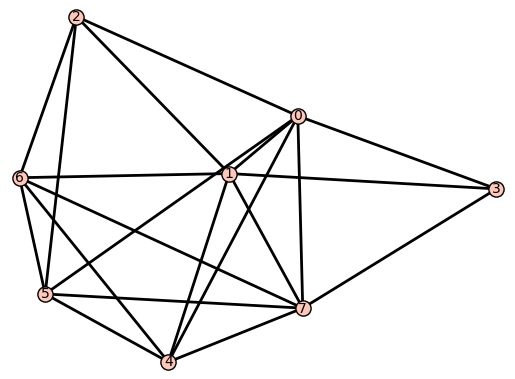


Showing LP solution graph H_lp


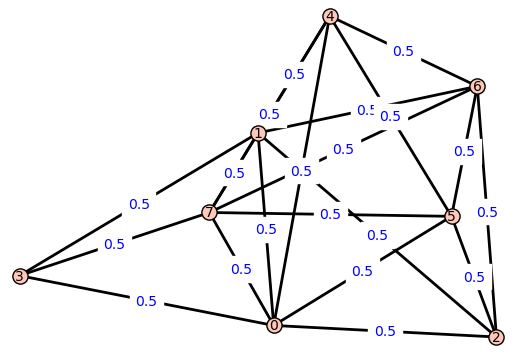


Showing root 1
Properties:
  Tree:            False
  Bipartite:       True
  Proper Interval: False
  Girth > 6:       False
  Block Graph:     False
  Comparability:   True
  Dismantlable:    False


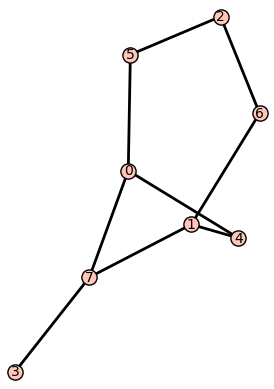

In [178]:
%matplotlib inline

def triangles_per_vertex(G):

    counts = {v: 0 for v in G.vertices()}

    for i, j, k in combinations(G.vertices(), 3):

        if G.has_edge(i,j) and G.has_edge(i,k) and G.has_edge(j,k):

            counts[i] += 1
            counts[j] += 1
            counts[k] += 1

    return counts

def display_graph(idx=None, n=None, G=None):

    if G is None:
        if idx is None or n is None:
            raise ValueError("Provide either G or (idx, n).")

        for i, H in enumerate(graph_gens.nauty_geng(f"-b {n}")):
            if i == idx:
                H = Graph(H)
                H.relabel(range(H.order()))

                G = graph_square(H)
                G.relabel(range(G.order()))
                break

        if G is None:
            print("Graph not found.")
            return
    else:
        G = Graph(G)

    G.relabel(range(G.order()))

    print("==============================")
    print(f"Graph {idx}")
    print("==============================")
    print("Vertices:", G.order())
    print("Edges:", G.size())

    H_lp = None
    lp_type = "unknown"

    try:

        m, x = cycle_linear_program(G, verbose=True)

        m.solve()

        sol = m.get_values(x)

        A = matrix([[sol[i, j] for j in range(G.order())] for i in range(G.order())])

        fractional = any(
            abs(A[i, j] - round(A[i, j])) > 1e-6
            for i in range(G.order())
            for j in range(G.order())
        )

        lp_type = "fractional" if fractional else "integer"

        H_lp = Graph(A, weighted=True)

        for (u, v, w) in H_lp.edges():
            H_lp.set_edge_label(u, v, round(w, 3))

        print("LP status: feasible")
        print("LP type:", lp_type)

    except MIPSolverException:

        print("LP status: infeasible")
        lp_type = "infeasible"

    root_info = find_all_square_roots(G)

    total_roots = root_info["labeled"]
    roots = root_info["non_isomorphic"]

    print("\nSquare roots")
    print("Total labeled:", total_roots)
    print("Non-isomorphic:", len(roots))

    print("\nTriangles per vertex in square graph G")
    tri_G = triangles_per_vertex(G)
    for v in sorted(tri_G):
        print(f"v{v}: {tri_G[v]}")

    print("\nShowing original graph G")

    p = G.plot(
        vertex_size=120,
        edge_thickness=2,
        vertex_labels=True,
        figsize=[8,8],
        title=f"G (Graph #{idx})"
    )
    display(p.matplotlib())

    if H_lp is not None:
        print("\nShowing LP solution graph H_lp")

        p = H_lp.plot(
            vertex_size=120,
            edge_thickness=2,
            edge_labels=True,
            vertex_labels=True,
            figsize=[8,8],
            title=f"H_lp ({lp_type})"
        )
        display(p.matplotlib())

    for i, H in enumerate(roots):

        print(f"\nShowing root {i+1}")

        is_tree = H.is_tree()
        is_bip = H.is_bipartite()

        is_interval = H.is_interval()
        is_claw_free = is_claw_free_graph(H)
        is_prop_int = is_interval and is_claw_free

        if is_tree:
            girth_gt6 = True
        else:
            g = H.girth()
            girth_gt6 = (g is not None and g > 6)

        is_block = H.is_block_graph()
        is_comp = H.is_comparability()
        is_dism = is_dismantlable_graph(H)

        print("Properties:")
        print(f"  Tree:            {is_tree}")
        print(f"  Bipartite:       {is_bip}")
        print(f"  Proper Interval: {is_prop_int}")
        print(f"  Girth > 6:       {girth_gt6}")
        print(f"  Block Graph:     {is_block}")
        print(f"  Comparability:   {is_comp}")
        print(f"  Dismantlable:    {is_dism}")

        p = H.plot(
            vertex_size=120,
            edge_thickness=2,
            vertex_labels=True,
            figsize=[8,8],
            title=f"Square root H{i+1}"
        )
        display(p.matplotlib())

display_graph(266, 8)